# Time Series Volatility

## Alcance y pregunta

¿Una varianza constante ignora agrupamiento de volatilidad condicional?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$h_t=\omega+\alpha\epsilon_{t-1}^2+\beta h_{t-1}$$

Se genera GARCH(1,1) con α=0.1, β variable y ω=(1−α−β) para fijar varianza incondicional en uno. Se comparan pronósticos oracle h y varianza expansiva en QLIKE fuera de muestra. El oracle conoce los parámetros; no es un modelo estimado.

### Supuestos de identificación

Innovaciones gaussianas y α+β<1; inicio h=1; sin saltos. QLIKE usa r²/h+log h.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

Se genera GARCH(1,1) con α=0.1, β variable y ω=(1−α−β) para fijar varianza incondicional en uno. Se comparan pronósticos oracle h y varianza expansiva en QLIKE fuera de muestra. El oracle conoce los parámetros; no es un modelo estimado.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=1200):
    alpha=.1;omega=1-alpha-level;h=np.ones(n);r=np.zeros(n);z=rng.normal(size=n)
    for t in range(1,n):h[t]=omega+alpha*r[t-1]**2+level*h[t-1];r[t]=np.sqrt(h[t])*z[t]
    t=np.arange(300,n);constant=np.cumsum(r*r)[t-1]/t
    oracle=np.mean(r[t]**2/h[t]+np.log(h[t]));naive=np.mean(r[t]**2/constant+np.log(constant))
    return {'QLIKE varianza expansiva':naive,'QLIKE oracle GARCH':oracle,'Varianza realizada':np.mean(r[t]**2)},(t,h[t])


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0.1, 0.3, 0.5, 0.7, 0.85]
METRICS=['QLIKE varianza expansiva', 'QLIKE oracle GARCH', 'Varianza realizada']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.5 ; semilla: 20261018


,Métrica,Valor
0,QLIKE varianza expansiva,0.958334
1,QLIKE oracle GARCH,0.947612
2,Varianza realizada,0.956249


## Sensibilidad y variación entre réplicas

**Eje:** Persistencia β.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.10,QLIKE varianza expansiva,0.99740,1.00594,0.04573,0.89726,1.07446,40,0.00723
1,0.10,QLIKE oracle GARCH,0.98682,0.99343,0.04466,0.89279,1.05736,40,0.00706
2,0.10,Varianza realizada,0.99523,1.00220,0.04529,0.90049,1.07101,40,0.00716
3,0.30,QLIKE varianza expansiva,0.99699,1.00384,0.04688,0.89235,1.07608,40,0.00741
4,0.30,QLIKE oracle GARCH,0.98536,0.99214,0.04613,0.88805,1.05830,40,0.00729
5,0.30,Varianza realizada,0.99473,1.00000,0.04639,0.89604,1.07246,40,0.00734
6,0.50,QLIKE varianza expansiva,0.99632,1.00061,0.04951,0.88250,1.07918,40,0.00783
7,0.50,QLIKE oracle GARCH,0.98183,0.98887,0.04899,0.87803,1.05940,40,0.00775
8,0.50,Varianza realizada,0.99390,0.99660,0.04894,0.88715,1.07525,40,0.00774
9,0.70,QLIKE varianza expansiva,0.99443,0.99779,0.05925,0.86822,1.09044,40,0.00937


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

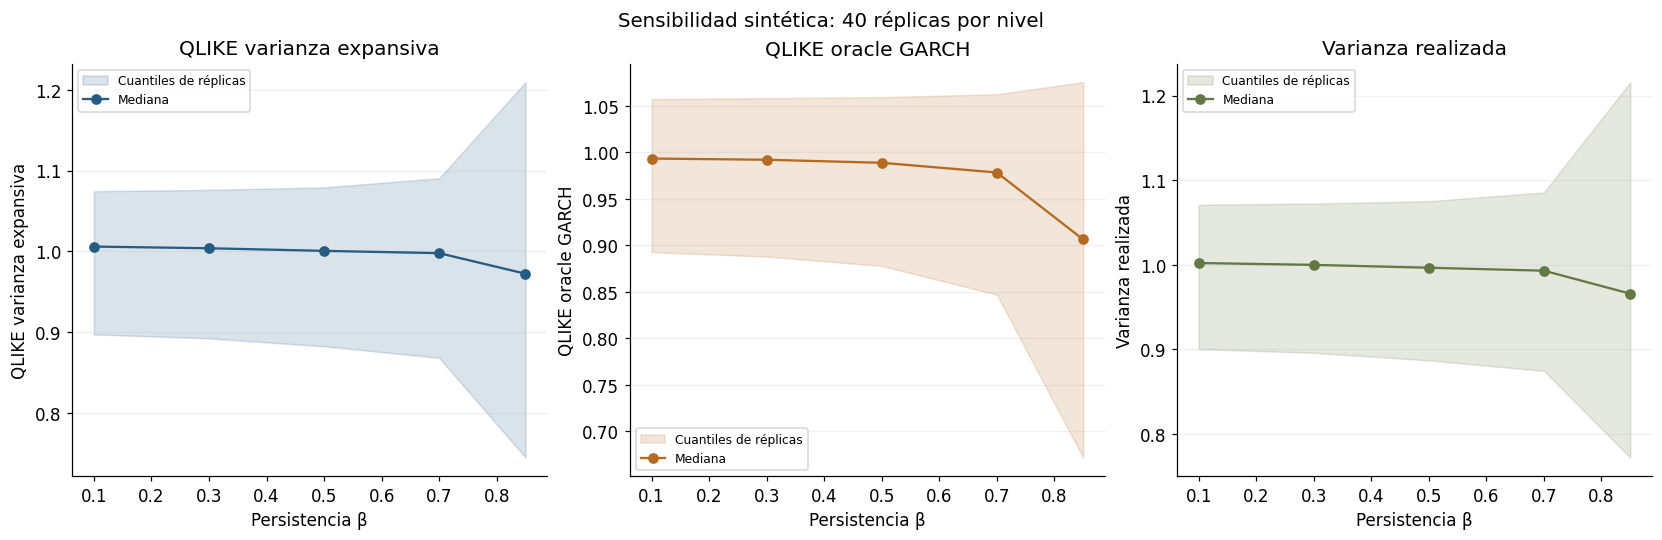

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Persistencia β',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


QLIKE varianza expansiva: mediana 1.00594 en nivel 0.1; 0.972329 en nivel 0.85.
  Último escenario: cuantiles [0.744975, 1.20927], media 0.980442, error MC de la media 0.0194.
QLIKE oracle GARCH: mediana 0.99343 en nivel 0.1; 0.90642 en nivel 0.85.
  Último escenario: cuantiles [0.67208, 1.07546], media 0.902884, error MC de la media 0.0169.
Varianza realizada: mediana 1.0022 en nivel 0.1; 0.965939 en nivel 0.85.
  Último escenario: cuantiles [0.772401, 1.21584], media 0.976127, error MC de la media 0.0189.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

La ventaja de un oracle no estima desempeño factible. Se requiere estimación QMLE y diagnósticos de residuos antes de una comparación operativa.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.